# Unfair Life — Mathematics, EDA & Traceability

This notebook documents the Phase 1 model **without retraining anything**: every number, figure and table is read
from the artifacts produced by the pipeline (`src/01_data_cleaner.py` → `src/04_evaluator.py`), so the report always
describes exactly the model that the inference API serves.

**Outputs** (for the academic report):
* `artifacts/figures/*.png` — EDA, SMOTE ablation, calibration, confusion matrices, decision policy, SHAP.
* `artifacts/latex/*.tex` — equations and tables, ready for `\input{}`.

Run the pipeline first, then: `jupyter nbconvert --to notebook --execute --inplace notebooks/01_math_and_eda.ipynb`

In [1]:
import json
import re
from pathlib import Path

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import Image, Latex, Markdown, display
from sklearn.metrics import confusion_matrix, precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, ART = ROOT / "data" / "processed", ROOT / "artifacts"
FIG, TEX = ART / "figures", ART / "latex"
FIG.mkdir(parents=True, exist_ok=True)
TEX.mkdir(parents=True, exist_ok=True)

cleaning = json.loads((DATA / "cleaning_report.json").read_text(encoding="utf-8"))
balancing = json.loads((DATA / "balancing_report.json").read_text(encoding="utf-8"))
comparison = json.loads((ART / "model_comparison.json").read_text(encoding="utf-8"))
report = json.loads((ART / "traceability_report.json").read_text(encoding="utf-8"))
schema = json.loads((ART / "feature_schema.json").read_text(encoding="utf-8"))
clean = pd.read_csv(DATA / "clean_adult.csv", keep_default_na=False)
val_pred = pd.read_parquet(ART / "validation_predictions.parquet")
test_pred = pd.read_parquet(ART / "test_predictions.parquet")
model = joblib.load(ART / "best_model.joblib")
X_test = pd.read_parquet(DATA / "X_test.parquet").astype("float64")

policy = report["decision_policy"]
LOWER, UPPER, THRESHOLD = policy["lower_bound"], policy["upper_bound"], policy["deterministic_threshold"]
TARGET = schema["target"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})

def save_fig(fig, name):
    path = FIG / f"{name}.png"
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

def save_tex(name, body):
    (TEX / f"{name}.tex").write_text(body.strip() + "\n", encoding="utf-8")
    display(Latex(body))

def tex_table(latex):
    # Escape '%' and '$' left raw by pandas to_latex: LaTeX reads them as a comment / math mode.
    return re.sub(r"(?<!\\)([%$])", r"\\\1", latex)

def pct(x):
    return f"{100 * x:.2f}\\%"

print(f"Model: {report['model']['name']} | band [{LOWER:.2f}, {UPPER:.2f}] | threshold {THRESHOLD:.4f}")

Model: Stacking (HGB + LR -> LR) [natural] | band [0.23, 0.78] | threshold 0.7782


## 1. Data integrity and exploratory analysis

Only the 1994 Adult Income census is used. Each cleaning action below is counted by `01_data_cleaner.py`.
`fnlwgt` is a census *sampling weight*, not a personal trait, so it is excluded from the model features.

In [2]:
summary = pd.DataFrame({
    "Step": ["Raw records", "Duplicate rows removed", "Rows dropped (missing numeric/label)", "Clean records",
             "Training rows (60%)", "Validation rows (20%)", "Test rows (20%)", "Positive rate (>50K)"],
    "Value": [f"{cleaning['raw_rows']:,}", f"{cleaning['duplicate_rows_removed']:,}",
              f"{cleaning['rows_dropped_missing_numeric_or_label']:,}", f"{cleaning['clean_rows']:,}",
              f"{balancing['splits']['train']['rows']:,}", f"{balancing['splits']['validation']['rows']:,}",
              f"{balancing['splits']['test']['rows']:,}", f"{cleaning['positive_rate']:.2%}"],
})
display(summary)
missing = pd.Series(cleaning["missing_values_by_column"], name="missing ('?')")
display(missing.to_frame())
save_tex("table_data", tex_table(summary.to_latex(index=False, caption="Data cleaning and split summary.", label="tab:data")))

,Step,Value
0,Raw records,"48,842"
1,Duplicate rows removed,52
2,Rows dropped (missing numeric/label),0
3,Clean records,"48,790"
4,Training rows (60%),"29,274"
5,Validation rows (20%),"9,758"
6,Test rows (20%),"9,758"
7,Positive rate (>50K),23.94%


,missing ('?')
workclass,2799
occupation,2809
native_country,857


<IPython.core.display.Latex object>

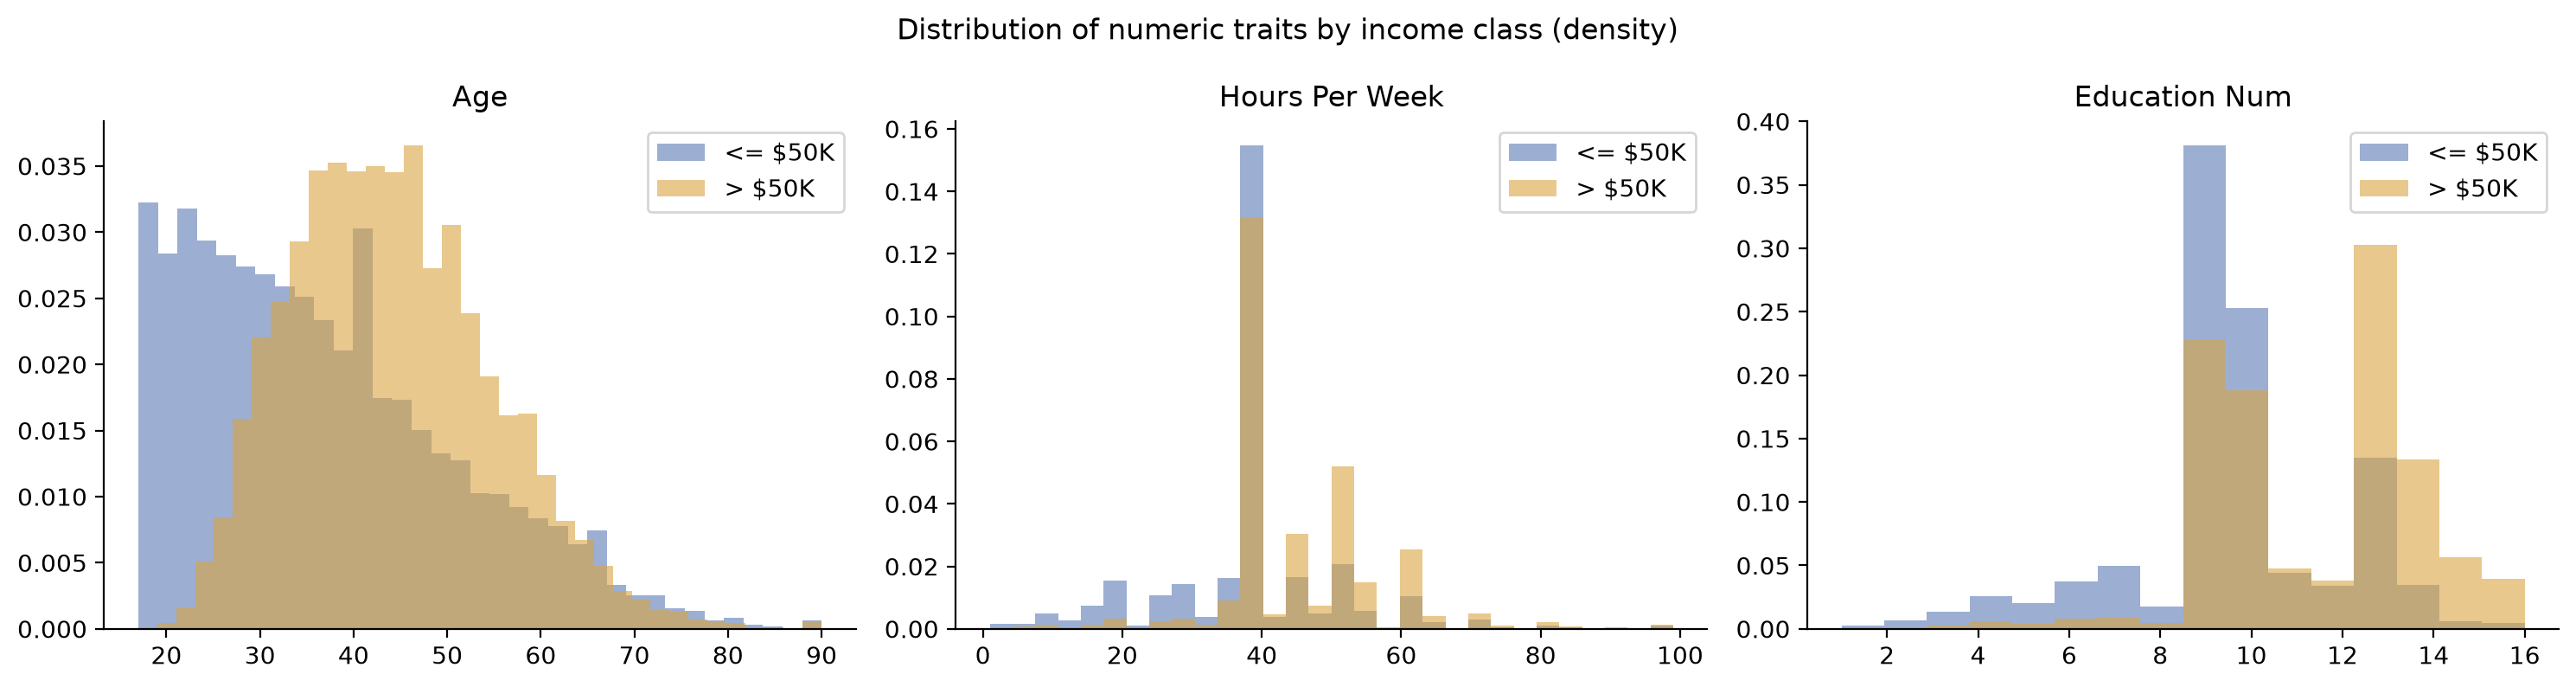

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, bins in zip(axes, ["age", "hours_per_week", "education_num"], [35, 30, 16]):
    for label, color in [(0, "#5a7bb5"), (1, "#d9a441")]:
        ax.hist(clean.loc[clean[TARGET] == label, column], bins=bins, alpha=0.6, density=True, color=color,
                label="> $50K" if label else "<= $50K")
    ax.set_title(column.replace("_", " ").title())
    ax.legend()
fig.suptitle("Distribution of numeric traits by income class (density)")
save_fig(fig, "eda_numeric_distributions")

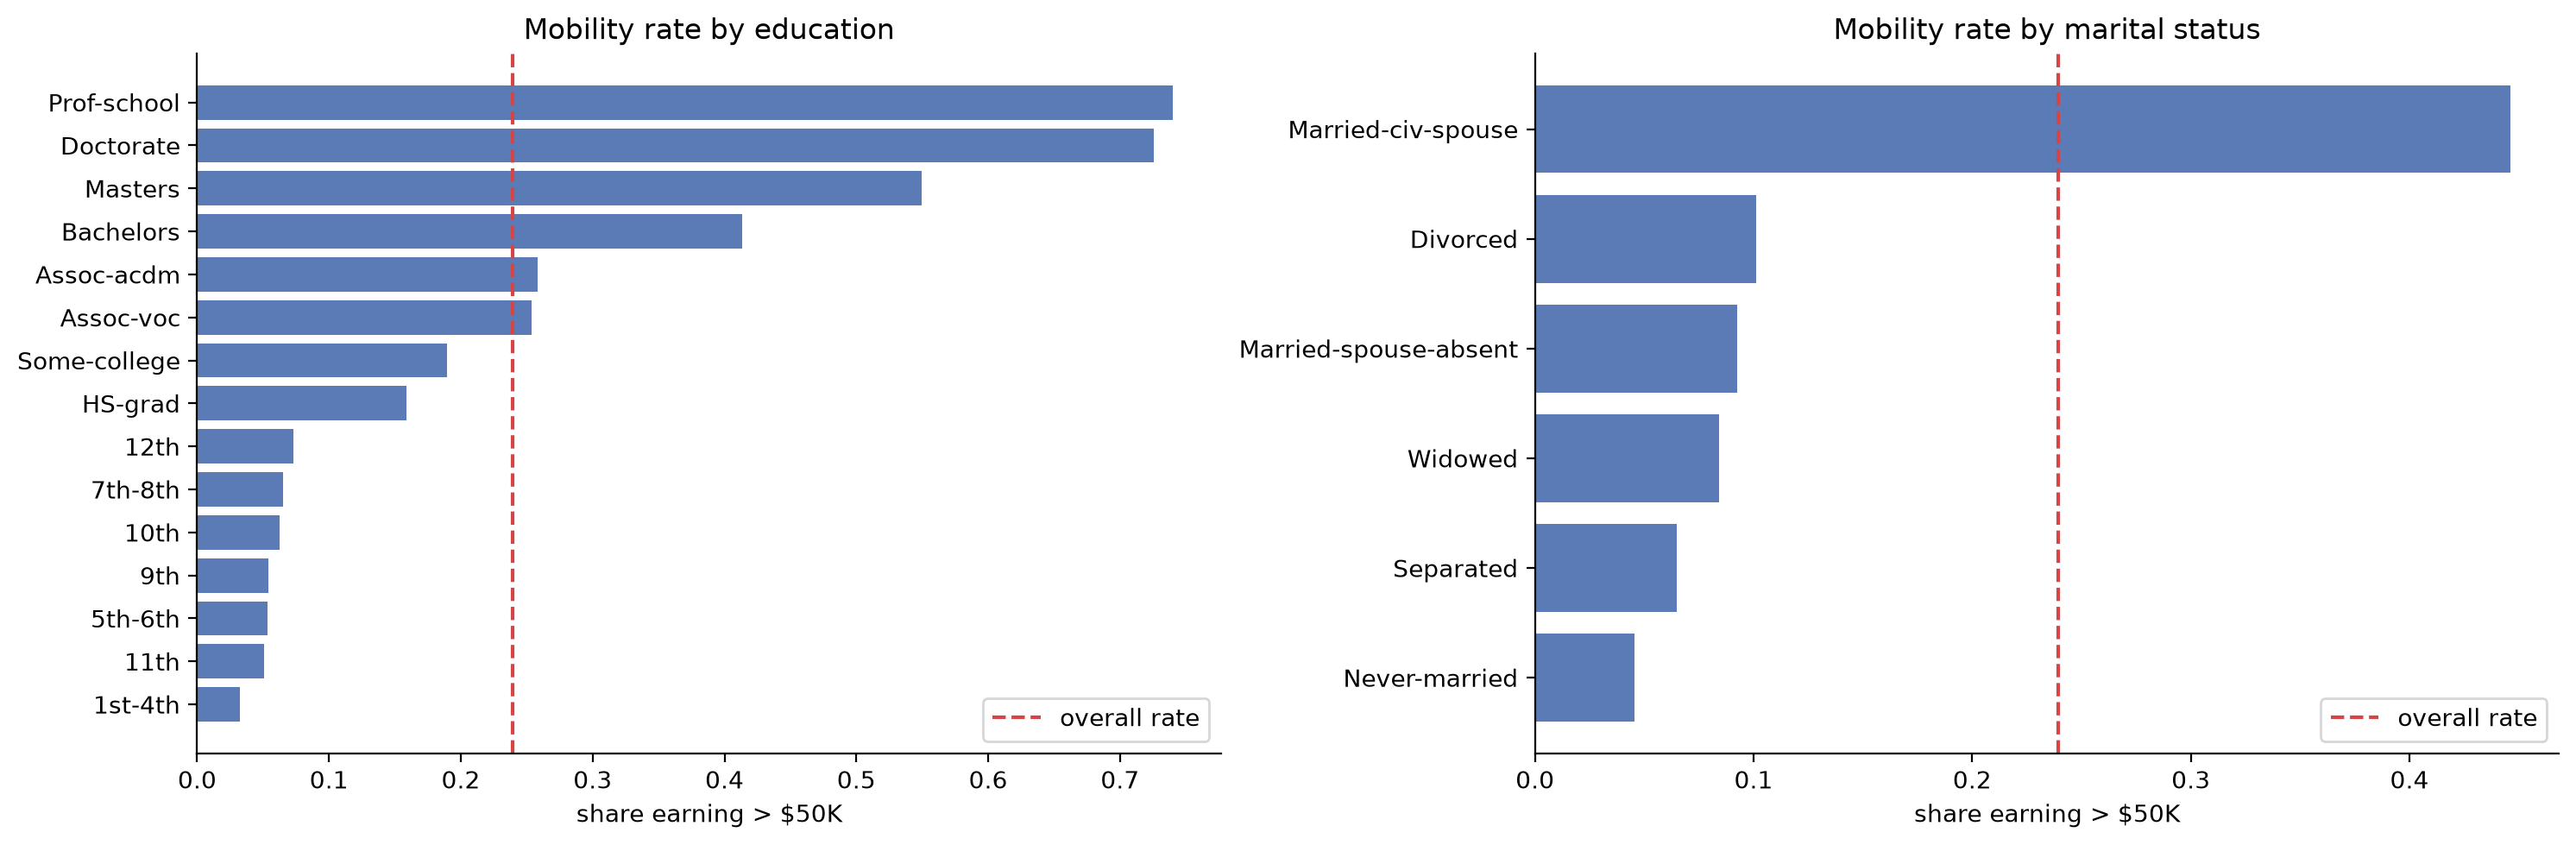

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, column in zip(axes, ["education", "marital_status"]):
    rates = clean.groupby(column)[TARGET].agg(["mean", "size"]).query("size >= 100").sort_values("mean")
    ax.barh(rates.index, rates["mean"], color="#5a7bb5")
    ax.axvline(cleaning["positive_rate"], color="#d64545", linestyle="--", label="overall rate")
    ax.set_xlabel("share earning > $50K")
    ax.set_title(f"Mobility rate by {column.replace('_', ' ')}")
    ax.legend()
save_fig(fig, "eda_rate_by_category")

## 2. Balancing: SMOTE applied, evaluated and rejected

The rubric requires class balancing. `02_balancer.py` applied **SMOTENC** to the training set (never to validation
or test), producing an exact 50/50 class split. Every model family was then trained on both the natural and the
SMOTE-balanced data and compared **on the untouched validation set**.

SMOTE creates each synthetic minority sample by interpolating between a minority sample $x_i$ and one of its
$k$ nearest minority neighbours $x_{z_i}$ (SMOTENC copies the neighbours' majority category for categorical traits):

<IPython.core.display.Latex object>

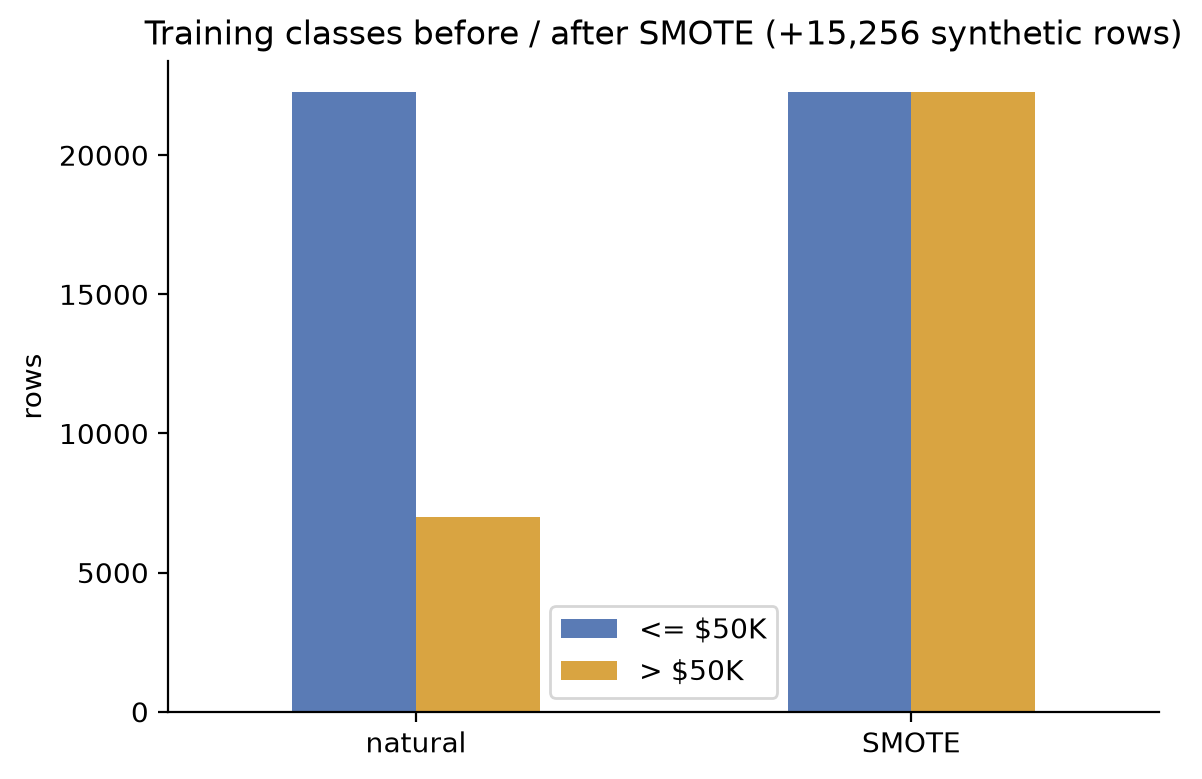

,average_precision_natural,average_precision_smote,delta_average_precision,ece_natural,ece_smote,mean_probability_natural,mean_probability_smote,observed_positive_rate
family,,,,,,,,
HistGradientBoosting,0.8303,0.7966,-0.0337,0.0096,0.0784,0.2413,0.3100,0.2394
KNN,0.6305,0.5971,-0.0335,0.0442,0.1209,0.2427,0.3398,0.2394
Logistic Regression,0.7676,0.7594,-0.0082,0.0080,0.1121,0.2394,0.3515,0.2394
Random Forest,0.7660,0.7160,-0.0500,0.0193,0.0665,0.2428,0.3031,0.2394
"SVM (RBF, calibrated)",0.7573,0.7362,-0.0211,0.0234,0.1048,0.2397,0.3442,0.2394


<IPython.core.display.Latex object>

In [5]:
save_tex("eq_smote", r'''
\begin{equation}
x_{\text{new}} = x_i + \lambda\,\bigl(x_{z_i} - x_i\bigr), \qquad \lambda \sim \mathcal{U}(0, 1),\quad x_{z_i} \in \mathrm{kNN}_k(x_i),\ k = %d
\end{equation}
''' % balancing["smote"]["k_neighbors"])

counts = pd.DataFrame({
    "natural": balancing["splits"]["train"]["class_counts"],
    "SMOTE": balancing["train_smote"]["class_counts"],
}).rename(index={"0": "<= $50K", "1": "> $50K"})
fig, ax = plt.subplots(figsize=(6, 4))
counts.T.plot.bar(ax=ax, color=["#5a7bb5", "#d9a441"], rot=0)
ax.set_title(f"Training classes before / after SMOTE (+{balancing['synthetic_rows']:,} synthetic rows)")
ax.set_ylabel("rows")
save_fig(fig, "smote_class_balance")

ablation = pd.DataFrame(comparison["smote_ablation"]).set_index("family")
ablation_view = ablation[["average_precision_natural", "average_precision_smote", "delta_average_precision",
                          "ece_natural", "ece_smote", "mean_probability_natural", "mean_probability_smote",
                          "observed_positive_rate"]].round(4)
display(ablation_view)
save_tex("table_smote_ablation", ablation_view.rename(columns=lambda c: c.replace("_", " ")).to_latex(
    caption="SMOTE ablation on the validation set: average precision (AP), expected calibration error (ECE) and mean predicted probability.",
    label="tab:smote", float_format="%.4f"))

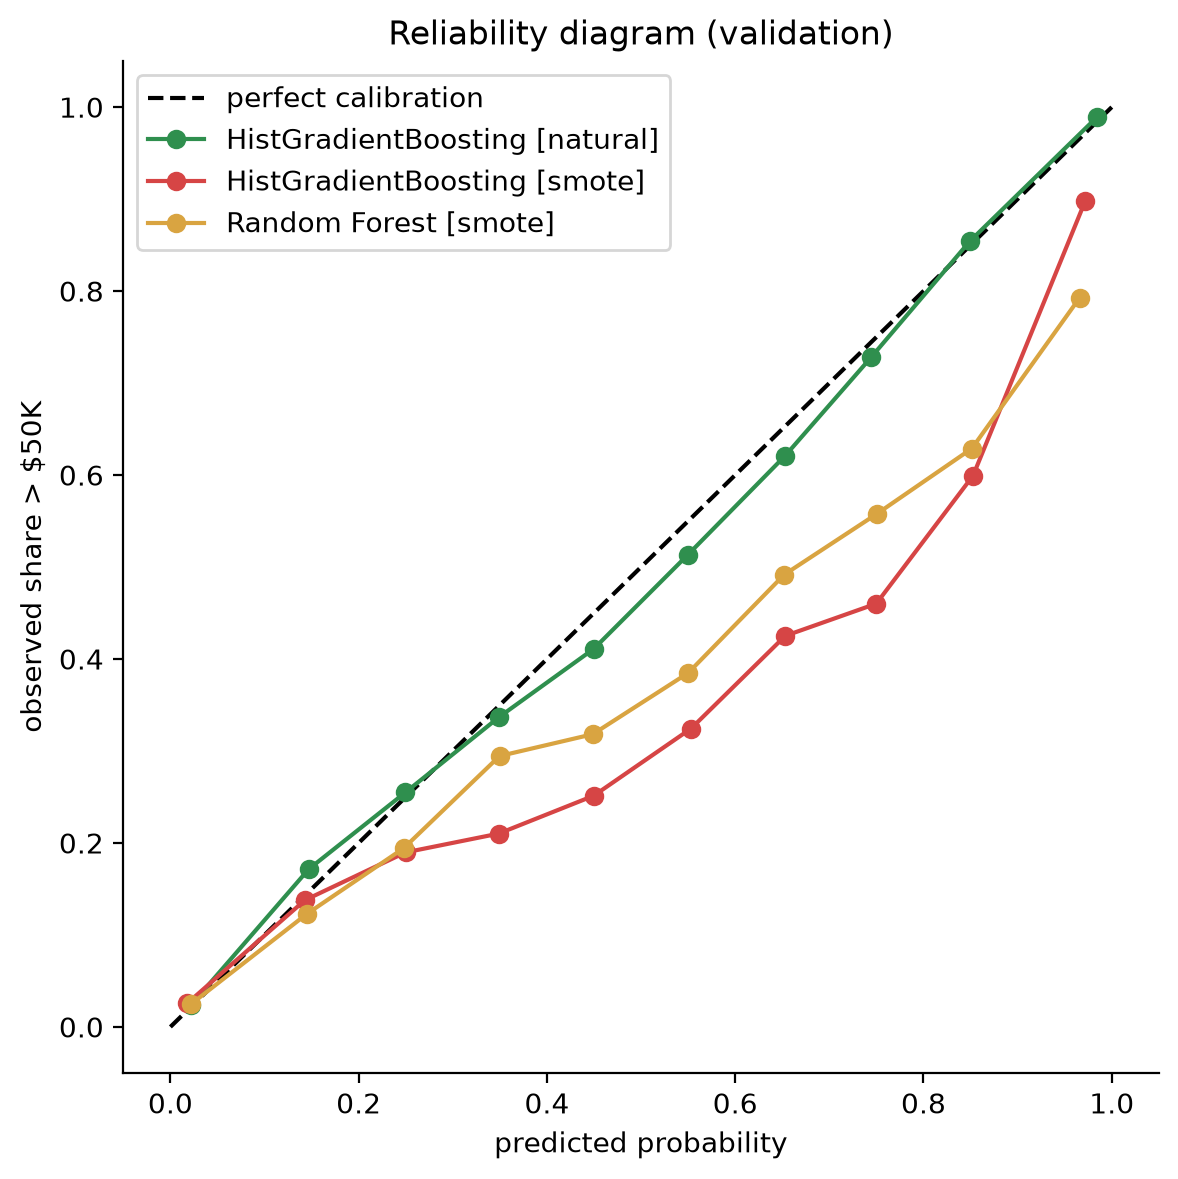

**Conclusion.** SMOTE lowered validation average precision in **every** family (from -0.0082 to -0.0500, worst: Random Forest) and inflated the predicted probabilities: the mean prediction rose from about 0.241 to 0.330, while the true positive rate is 0.239. Because the game turns the probability into a weighted coin flip, calibrated probabilities are essential, so SMOTE was **rejected** for the deployed model, which is trained on the natural distribution.

In [6]:
from sklearn.calibration import calibration_curve

y_val = val_pred[TARGET].to_numpy()
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
for name, color in [("HistGradientBoosting [natural]", "#2f8f4e"), ("HistGradientBoosting [smote]", "#d64545"),
                    ("Random Forest [smote]", "#d9a441")]:
    frac, mean = calibration_curve(y_val, val_pred[name], n_bins=10)
    ax.plot(mean, frac, "o-", color=color, label=name)
ax.set_xlabel("predicted probability")
ax.set_ylabel("observed share > $50K")
ax.set_title("Reliability diagram (validation)")
ax.legend()
save_fig(fig, "calibration_smote_vs_natural")

worst = ablation["delta_average_precision"].idxmin()
display(Markdown(
    f"**Conclusion.** SMOTE lowered validation average precision in **every** family "
    f"(from {ablation['delta_average_precision'].max():+.4f} to {ablation['delta_average_precision'].min():+.4f}, worst: {worst}) "
    f"and inflated the predicted probabilities: the mean prediction rose from about "
    f"{ablation['mean_probability_natural'].mean():.3f} to {ablation['mean_probability_smote'].mean():.3f}, "
    f"while the true positive rate is {ablation['observed_positive_rate'].iloc[0]:.3f}. Because the game turns the "
    f"probability into a weighted coin flip, calibrated probabilities are essential, so SMOTE was **rejected** for the "
    f"deployed model, which is trained on the natural distribution."))

## 3. Model comparison (validation set)

Single candidates are ranked by validation **average precision** (area under the precision–recall curve), tie-break
on the Brier score. The deployed model is the **stacking ensemble** of section 4, whose architecture was fixed by
design and justified by the stacking ablation. The test set was not used for any choice.

In [7]:
rows = []
for m in comparison["models"]:
    v = m["validation"]
    rows.append({"model": m["name"], "AP": v["average_precision"], "ROC-AUC": v["roc_auc"], "Brier": v["brier"],
                 "ECE": v["ece"], "Acc@0.5": v["accuracy_at_0_5"], "Prec@0.5": v["precision_at_0_5"],
                 "Rec@0.5": v["recall_at_0_5"]})
models = pd.DataFrame(rows).sort_values("AP", ascending=False).set_index("model").round(4)
display(models)
save_tex("table_models", models.to_latex(caption="Candidate models on the validation set (selected: %s)." % comparison["selected_model"],
                                          label="tab:models", float_format="%.4f"))

,AP,ROC-AUC,Brier,ECE,Acc@0.5,Prec@0.5,Rec@0.5
model,,,,,,,
Stacking (HGB + LR -> LR) [natural],0.8303,0.9280,0.0879,0.0073,0.8729,0.7713,0.6670
HistGradientBoosting [natural],0.8303,0.9278,0.0881,0.0096,0.8730,0.7698,0.6699
HistGradientBoosting (class-weighted) [natural],0.8296,0.9277,0.1095,0.1003,0.8322,0.6054,0.8592
HistGradientBoosting [smote],0.7966,0.9101,0.1136,0.0784,0.8346,0.6205,0.7958
Logistic Regression [natural],0.7676,0.9058,0.1018,0.0080,0.8522,0.7331,0.6019
Random Forest [natural],0.7660,0.9030,0.1029,0.0193,0.8514,0.7189,0.6229
Logistic Regression [smote],0.7594,0.9002,0.1278,0.1121,0.8071,0.5665,0.8275
"SVM (RBF, calibrated) [natural]",0.7573,0.9013,0.1049,0.0234,0.8483,0.7319,0.5783
"SVM (RBF, calibrated) [smote]",0.7362,0.8883,0.1313,0.1048,0.8088,0.5748,0.7727


<IPython.core.display.Latex object>

## 4. The mathematical model

The deployed classifier is a **two-layer stacking ensemble**. Its first layer holds a histogram gradient-boosted tree
ensemble and a logistic regression; its second layer, a logistic regression, combines their **log-odds**.

The gradient-boosted base learner builds an additive model in log-odds space, each tree $f_m$ fitted to the negative
gradient of the binary log-loss, with shrinkage $\nu$:

In [8]:
hgb = model.named_estimators_["hgb"]  # the base learner refitted on the full training set
meta = comparison["stacking"]["meta_learner"]
save_tex("eq_gradient_boosting", r'''
\begin{align}
F_0(x) &= \log\frac{\bar{y}}{1-\bar{y}}, \qquad
F_M(x) = F_0(x) + \nu \sum_{m=1}^{M} f_m(x), \qquad \nu = %.2f,\ M = %d \\
\hat{p}(x) &= \sigma\bigl(F_M(x)\bigr) = \frac{1}{1 + e^{-F_M(x)}} \\
\mathcal{L} &= -\frac{1}{n}\sum_{i=1}^{n}\Bigl[y_i \log \hat{p}(x_i) + (1-y_i)\log\bigl(1-\hat{p}(x_i)\bigr)\Bigr] + \lambda \lVert w \rVert_2^2,
\qquad \lambda = %.1f \\
f_m &= \arg\min_{f} \sum_{i=1}^{n} \Bigl(g_i\, f(x_i) + \tfrac{1}{2} h_i\, f(x_i)^2\Bigr), \quad
g_i = \hat{p}_{m-1}(x_i) - y_i,\ \ h_i = \hat{p}_{m-1}(x_i)\bigl(1-\hat{p}_{m-1}(x_i)\bigr)
\end{align}
''' % (hgb.learning_rate, hgb.n_iter_, hgb.l2_regularization))

# Layer 2: the meta-learner combines the base learners' log-odds; it is fitted on out-of-fold log-odds.
save_tex("eq_stacking", r'''
\begin{align}
F(x) &= b + w_{\text{hgb}}\, F_{\text{hgb}}(x) + w_{\text{lr}}\, F_{\text{lr}}(x), \qquad
F_{\text{lr}}(x) = \beta_0 + \sum_{j} \beta_j\, \frac{x_j - \mu_j}{s_j}, \qquad
\hat{p}(x) = \sigma\bigl(F(x)\bigr) \\
(b, w) &= \arg\min_{b,\,w}\ -\frac{1}{n}\sum_{i=1}^{n}\Bigl[y_i \log \sigma\bigl(F^{\text{oof}}(x_i)\bigr)
+ (1-y_i)\log\Bigl(1-\sigma\bigl(F^{\text{oof}}(x_i)\bigr)\Bigr)\Bigr] + \frac{1}{2C}\lVert w \rVert_2^2,
\qquad K = %d \text{ folds} \\
b &= %.4f, \qquad w_{\text{hgb}} = %.4f, \qquad w_{\text{lr}} = %.4f
\end{align}
''' % (model.cv.n_splits, meta["intercept"], meta["hgb"], meta["lr"]))

save_tex("eq_metrics", r'''
\begin{align}
\text{Precision} &= \frac{TP}{TP + FP}, \qquad \text{Recall} = \frac{TP}{TP + FN}, \qquad
F_1 = \frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision} + \text{Recall}}, \qquad
\text{Accuracy} = \frac{TP + TN}{N} \\
\text{Brier} &= \frac{1}{N}\sum_{i=1}^{N}\bigl(\hat{p}_i - y_i\bigr)^2, \qquad
\text{ECE} = \sum_{b=1}^{B} \frac{|S_b|}{N}\,\Bigl|\,\overline{\hat{p}}_{S_b} - \overline{y}_{S_b}\Bigr|,\ B = 10
\end{align}
''')

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

### Selective classification (the deployed decision policy)

The model only decides when it is confident. The band $[\ell, u]$ is chosen on the validation set $V$ as the
widest-coverage pair whose two deterministic outcomes both reach 95 % precision:

In [9]:
sel = report["selective_classification"]["test"]
save_tex("eq_selective_classification", r'''
\begin{align}
(\ell^*, u^*) &= \arg\max_{\ell < u}\ \frac{\bigl|\{i \in V : \hat{p}_i \le \ell \ \lor\ \hat{p}_i \ge u\}\bigr|}{|V|}
\quad \text{s.t.}\quad
\Pr\bigl(y = 1 \mid \hat{p} \ge u\bigr) \ge 0.95,\ \ \Pr\bigl(y = 0 \mid \hat{p} \le \ell\bigr) \ge 0.95 \\
(\ell^*, u^*) &= (%.2f,\ %.2f) \\
\text{decision}(x) &= \begin{cases}
\text{mobility} & \hat{p}(x) \ge u^* \\
\text{no mobility} & \hat{p}(x) \le \ell^* \\
\text{mobility with probability } \hat{p}(x) & \ell^* < \hat{p}(x) < u^* \quad \text{(systemic luck)}
\end{cases}
\end{align}
''' % (LOWER, UPPER))

save_tex("eq_wilson", r'''
\begin{equation}
\text{CI}_{95\%}(\hat{\pi}) = \frac{\hat{\pi} + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat{\pi}(1-\hat{\pi})}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}},
\qquad z = 1.96
\end{equation}
''')

game = report["game_mechanic"]["test"]
save_tex("eq_game_accuracy", r'''
\begin{equation}
\mathbb{E}[\text{Accuracy}_{\text{game}}] = \frac{1}{N}\Biggl[\sum_{i \notin \text{band}} \mathbb{1}\bigl(\text{decision}_i = y_i\bigr)
+ \sum_{i \in \text{band}} \Bigl(y_i\,\hat{p}_i + (1-y_i)(1-\hat{p}_i)\Bigr)\Biggr] = %s
\end{equation}
''' % pct(game["expected_accuracy_all_players"]))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

## 5. Results on the untouched test set

In [10]:
boot = report["selective_classification"]["bootstrap"]
thr = report["deterministic_threshold"]["test"]
base = report["reference_at_0_5"]["test"]
results = pd.DataFrame([
    ["Selective classification", "Coverage", sel["coverage"], boot["coverage_95ci"]],
    ["Selective classification", "Accuracy on decided cases", sel["accuracy_on_covered"], sel["accuracy_on_covered_95ci"]],
    ["Selective classification", "Precision 'mobility'", sel["precision_mobility"], sel["precision_mobility_95ci"]],
    ["Selective classification", "Precision 'no mobility'", sel["precision_no_mobility"], sel["precision_no_mobility_95ci"]],
    ["Game (coin flip in band)", "Expected accuracy, all players", game["expected_accuracy_all_players"], game["simulated_accuracy_95_range"]],
    [f"Threshold t = {thr['threshold']:.4f}", "Precision", thr["precision"], thr["precision_95ci"]],
    [f"Threshold t = {thr['threshold']:.4f}", "Recall", thr["recall"], None],
    ["Threshold t = 0.50 (reference)", "Accuracy", base["accuracy"], None],
], columns=["policy", "metric", "value", "95% interval"])
results["value"] = results["value"].map(lambda v: f"{v:.2%}")
results["95% interval"] = results["95% interval"].map(lambda ci: "" if ci is None else f"{ci[0]:.2%} - {ci[1]:.2%}")
display(results)
save_tex("table_results", tex_table(results.to_latex(index=False, caption="Test-set results (9,758 unseen people).", label="tab:results")))

,policy,metric,value,95% interval
0,Selective classification,Coverage,74.50%,73.66% - 75.38%
1,Selective classification,Accuracy on decided cases,95.45%,94.94% - 95.90%
2,Selective classification,Precision 'mobility',95.69%,94.18% - 96.82%
3,Selective classification,Precision 'no mobility',95.41%,94.87% - 95.90%
4,Game (coin flip in band),"Expected accuracy, all players",85.22%,84.74% - 85.68%
5,Threshold t = 0.7782,Precision,95.49%,93.96% - 96.65%
6,Threshold t = 0.7782,Recall,38.06%,
7,Threshold t = 0.50 (reference),Accuracy,87.67%,


<IPython.core.display.Latex object>

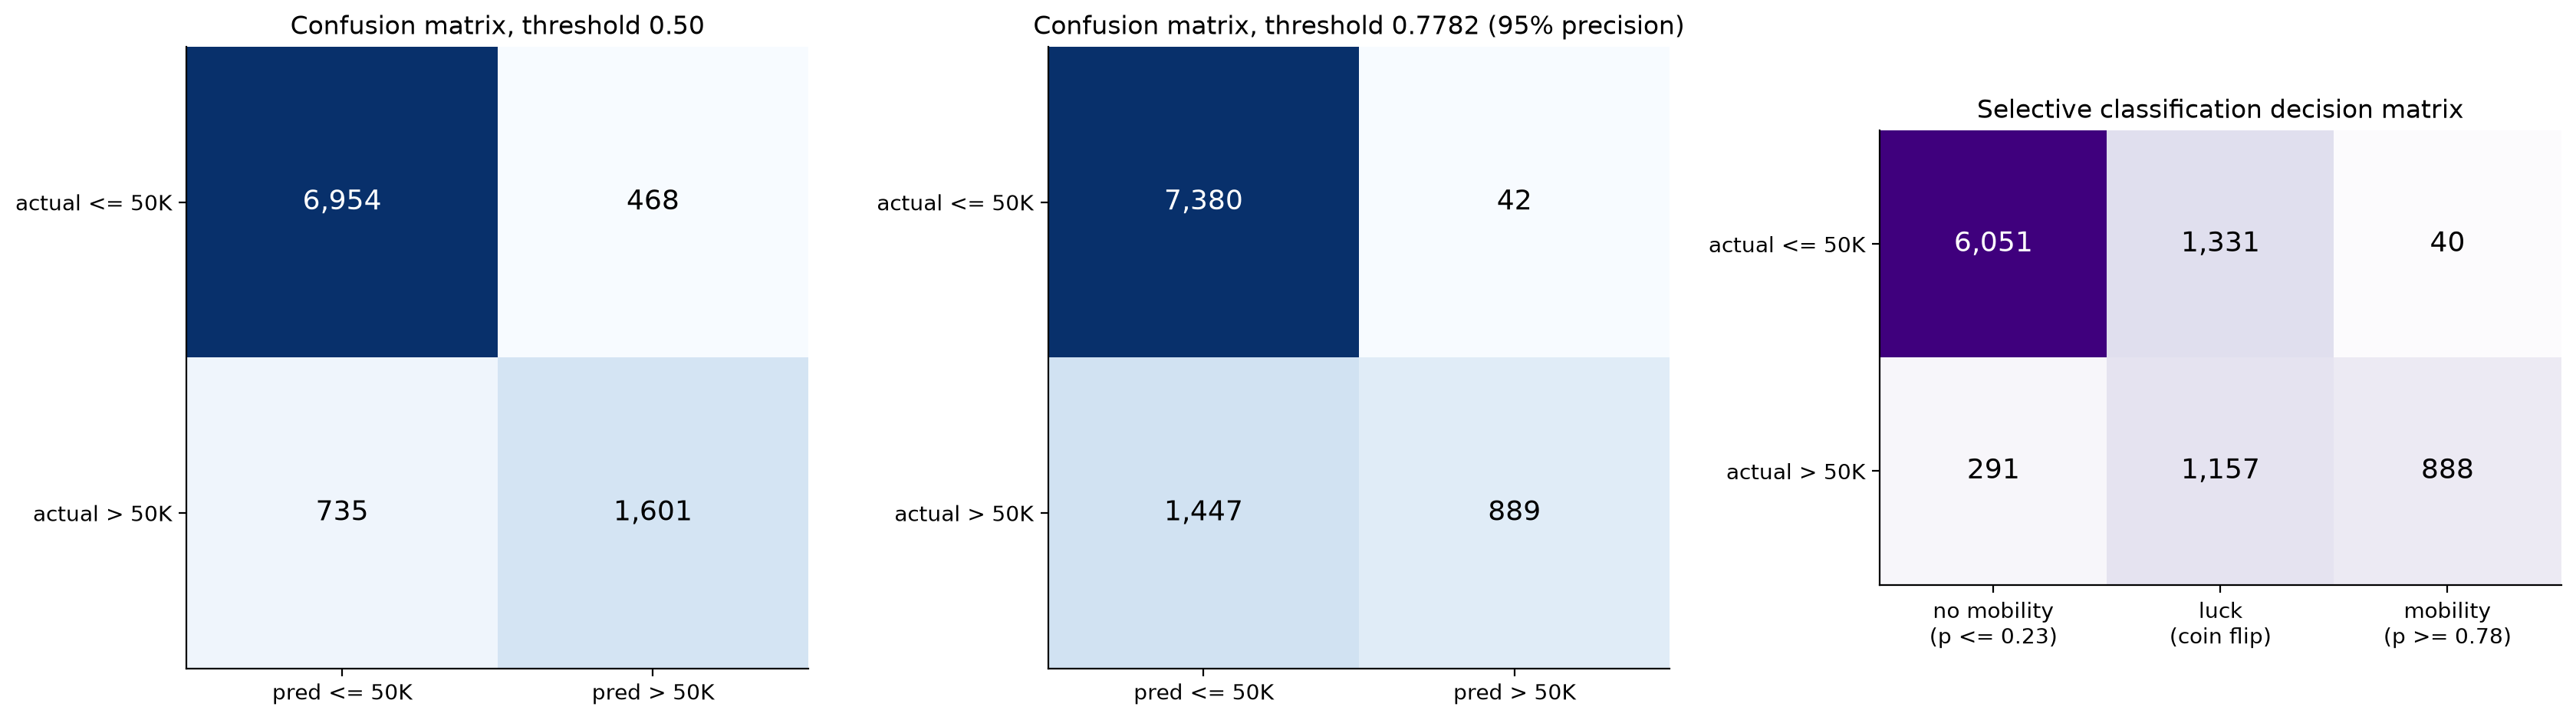

In [11]:
p, y = test_pred["probability"].to_numpy(), test_pred[TARGET].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

for ax, (title, t) in zip(axes[:2], [("threshold 0.50", 0.5), (f"threshold {THRESHOLD:.4f} (95% precision)", THRESHOLD)]):
    cm = confusion_matrix(y, (p >= t).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for (r, c), v in np.ndenumerate(cm):
        ax.text(c, r, f"{v:,}", ha="center", va="center", fontsize=13, color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["pred <= 50K", "pred > 50K"]); ax.set_yticks([0, 1], ["actual <= 50K", "actual > 50K"])
    ax.set_title(f"Confusion matrix, {title}")

m = sel["decision_matrix"]
grid = np.array([[m["actual_no_mobility"][k] for k in ("predicted_no", "luck", "predicted_yes")],
                 [m["actual_mobility"][k] for k in ("predicted_no", "luck", "predicted_yes")]])
axes[2].imshow(grid, cmap="Purples")
for (r, c), v in np.ndenumerate(grid):
    axes[2].text(c, r, f"{v:,}", ha="center", va="center", fontsize=13, color="white" if v > grid.max() / 2 else "black")
axes[2].set_xticks([0, 1, 2], [f"no mobility\n(p <= {LOWER:.2f})", "luck\n(coin flip)", f"mobility\n(p >= {UPPER:.2f})"])
axes[2].set_yticks([0, 1], ["actual <= 50K", "actual > 50K"])
axes[2].set_title("Selective classification decision matrix")
save_fig(fig, "confusion_matrices")

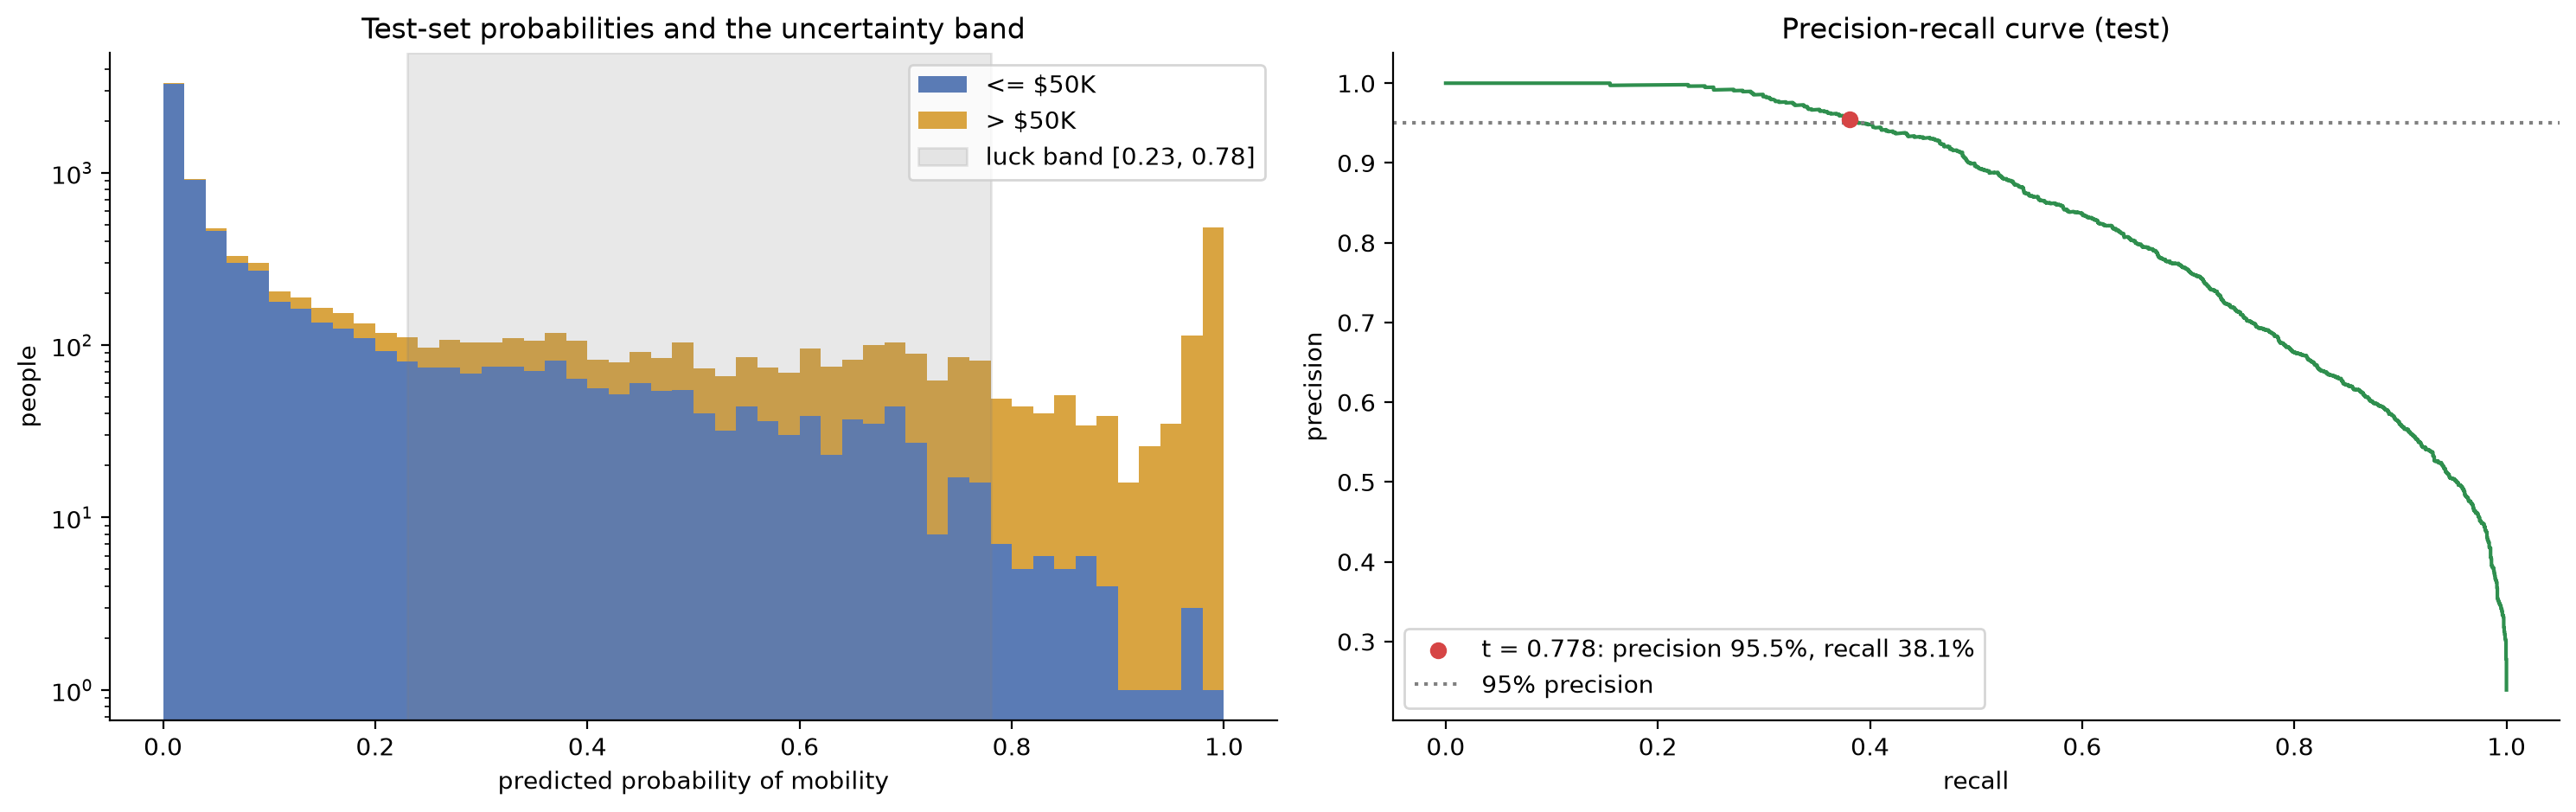

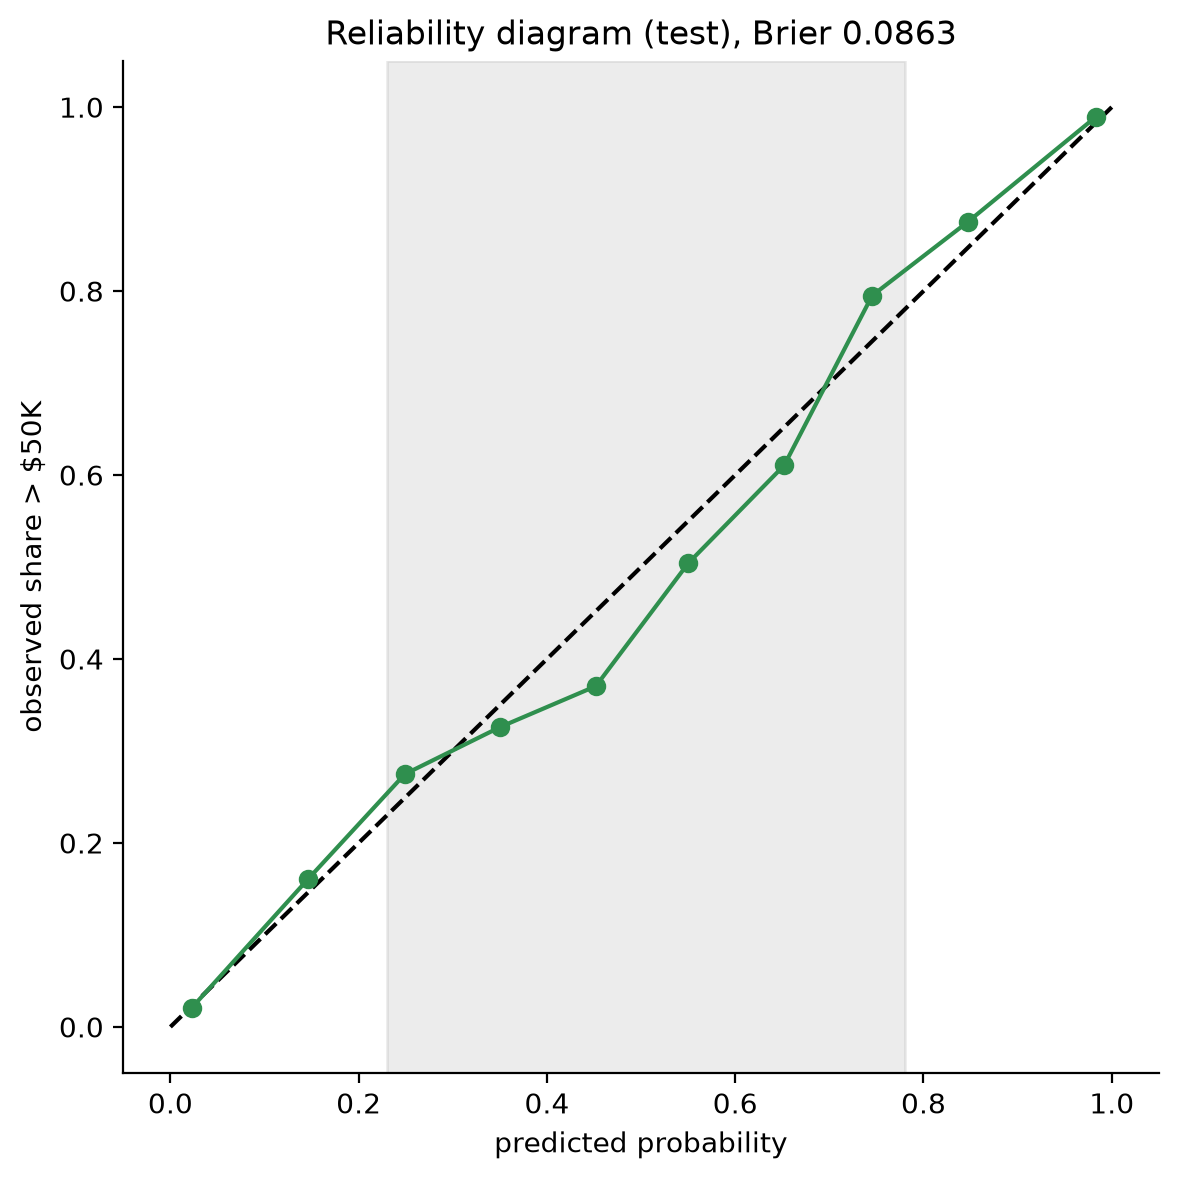

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
ax.hist([p[y == 0], p[y == 1]], bins=50, stacked=True, color=["#5a7bb5", "#d9a441"], label=["<= $50K", "> $50K"])
ax.axvspan(LOWER, UPPER, color="grey", alpha=0.18, label=f"luck band [{LOWER:.2f}, {UPPER:.2f}]")
ax.set_xlabel("predicted probability of mobility"); ax.set_ylabel("people"); ax.set_yscale("log")
ax.set_title("Test-set probabilities and the uncertainty band"); ax.legend()

precision, recall, thresholds = precision_recall_curve(y, p)
ax = axes[1]
ax.plot(recall, precision, color="#2f8f4e")
ax.scatter([thr["recall"]], [thr["precision"]], color="#d64545", zorder=3,
           label=f"t = {THRESHOLD:.3f}: precision {thr['precision']:.1%}, recall {thr['recall']:.1%}")
ax.axhline(0.95, color="grey", linestyle=":", label="95% precision")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision-recall curve (test)"); ax.legend()
save_fig(fig, "decision_policy")

from sklearn.calibration import calibration_curve
frac, mean = calibration_curve(y, p, n_bins=10)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--"); ax.plot(mean, frac, "o-", color="#2f8f4e")
ax.axvspan(LOWER, UPPER, color="grey", alpha=0.15)
ax.set_xlabel("predicted probability"); ax.set_ylabel("observed share > $50K")
ax.set_title(f"Reliability diagram (test), Brier {report['calibration']['test']['brier']:.4f}")
save_fig(fig, "calibration_test")

## 6. Explainability: SHAP values

SHAP attributes each prediction to the features using Shapley values from cooperative game theory, in **log-odds**
units. The ensemble is explained **exactly**: its log-odds are an affine combination of two additive scores,
$F = b + w_{\text{hgb}} F_{\text{hgb}} + w_{\text{lr}} F_{\text{lr}}$, so by the *linearity* axiom of Shapley values
$\phi_j(F) = w_{\text{hgb}}\,\phi_j(F_{\text{hgb}}) + w_{\text{lr}}\,\phi_j(F_{\text{lr}})$.
The gradient-boosting term is computed with interventional `TreeExplainer`, and the linear term in closed form,
$\phi_j(F_{\text{lr}}) = (\beta_j / s_j)\,(x_j - \mathbb{E}[x_j])$, both against the same background sample of
training rows. Local accuracy then holds for the ensemble: $F(x) = \phi_0 + \sum_j \phi_j$.

<IPython.core.display.Latex object>

 68%|==============      | 1361/2000 [00:11<00:05]       

 75%|===============     | 1492/2000 [00:12<00:04]       

 81%|================    | 1615/2000 [00:13<00:03]       

 87%|=================   | 1748/2000 [00:14<00:02]       

 94%|=================== | 1879/2000 [00:15<00:00]       

Local accuracy check for the ensemble (max |sum(phi) + phi_0 - F(x)|): 7.62e-08


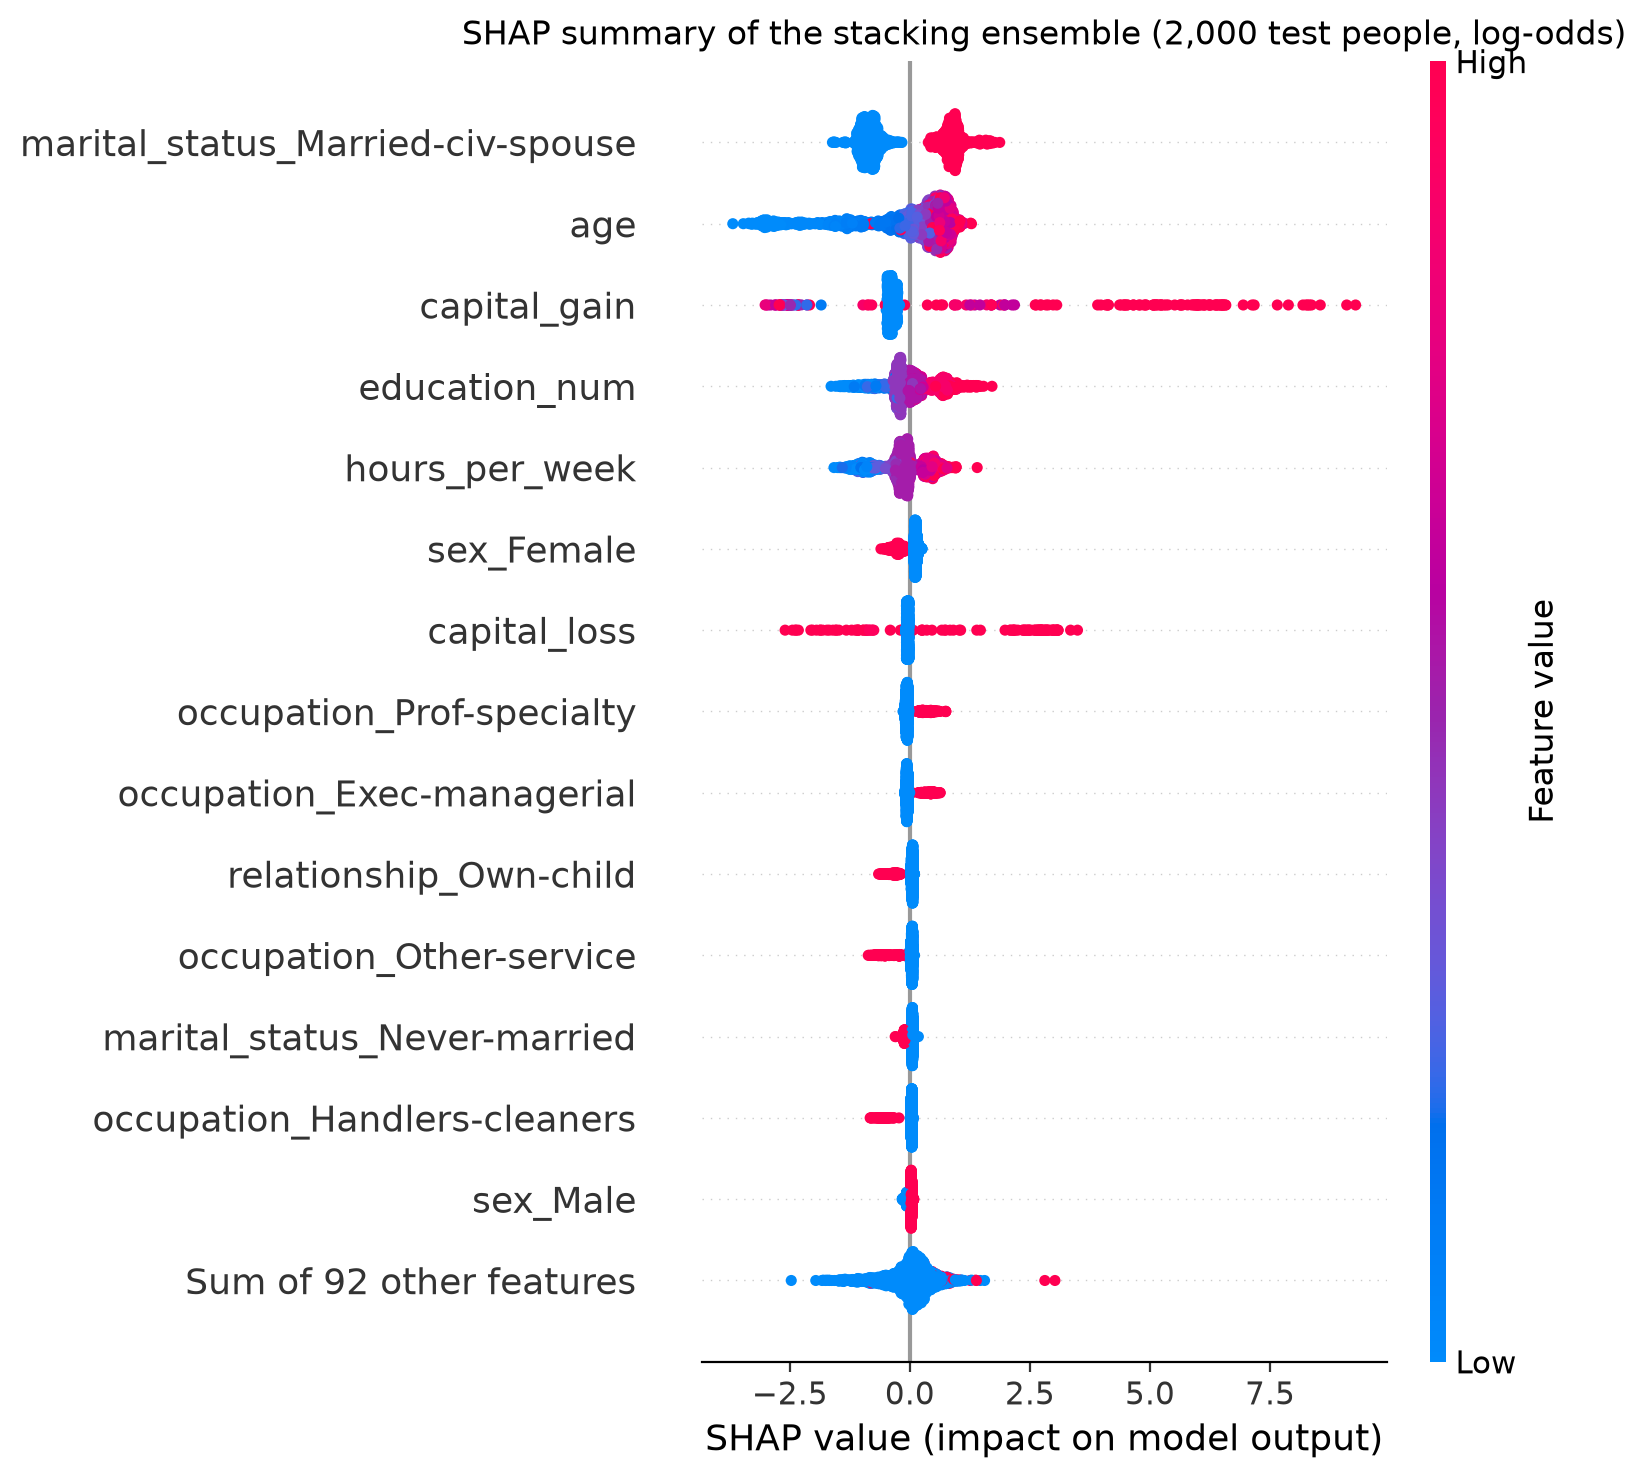

In [13]:
save_tex("eq_shapley", r'''
\begin{equation}
\phi_j(x) = \sum_{S \subseteq F \setminus \{j\}} \frac{|S|!\,\bigl(|F| - |S| - 1\bigr)!}{|F|!}\Bigl[v_x\bigl(S \cup \{j\}\bigr) - v_x(S)\Bigr],
\qquad F(x) = \phi_0 + \sum_{j \in F} \phi_j(x)
\end{equation}
''')

sample = X_test.sample(2000, random_state=42)
# 100 rows: TreeExplainer's interventional default; the linear term must use the same background.
background = pd.read_parquet(DATA / "X_train.parquet").astype("float64").sample(100, random_state=42)
hgb, lr_pipe = model.named_estimators_["hgb"], model.named_estimators_["lr"]

# Layer 1a: exact interventional TreeSHAP of the gradient-boosting log-odds.
tree = shap.TreeExplainer(hgb, data=background, feature_perturbation="interventional")(sample)
# Layer 1b: exact SHAP of the linear log-odds, phi_j = (beta_j / s_j) * (x_j - E_background[x_j]).
scaler, lr = lr_pipe.named_steps["scaler"], lr_pipe.named_steps["model"]
slope = lr.coef_.ravel() / scaler.scale_
phi_lr = (sample.to_numpy() - background.mean().to_numpy()) * slope
base_lr = float(lr_pipe.decision_function(background).mean())
# Layer 2: Shapley linearity combines both attributions with the meta-learner weights.
values = meta["hgb"] * tree.values + meta["lr"] * phi_lr
base = meta["intercept"] + meta["hgb"] * np.asarray(tree.base_values) + meta["lr"] * base_lr
explanation = shap.Explanation(values=values, base_values=base, data=sample.to_numpy(), feature_names=list(sample.columns))
error = np.abs(values.sum(axis=1) + base - model.decision_function(sample)).max()
print(f"Local accuracy check for the ensemble (max |sum(phi) + phi_0 - F(x)|): {error:.2e}")

plt.figure()
shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.title("SHAP summary of the stacking ensemble (2,000 test people, log-odds)")
save_fig(plt.gcf(), "shap_beeswarm")

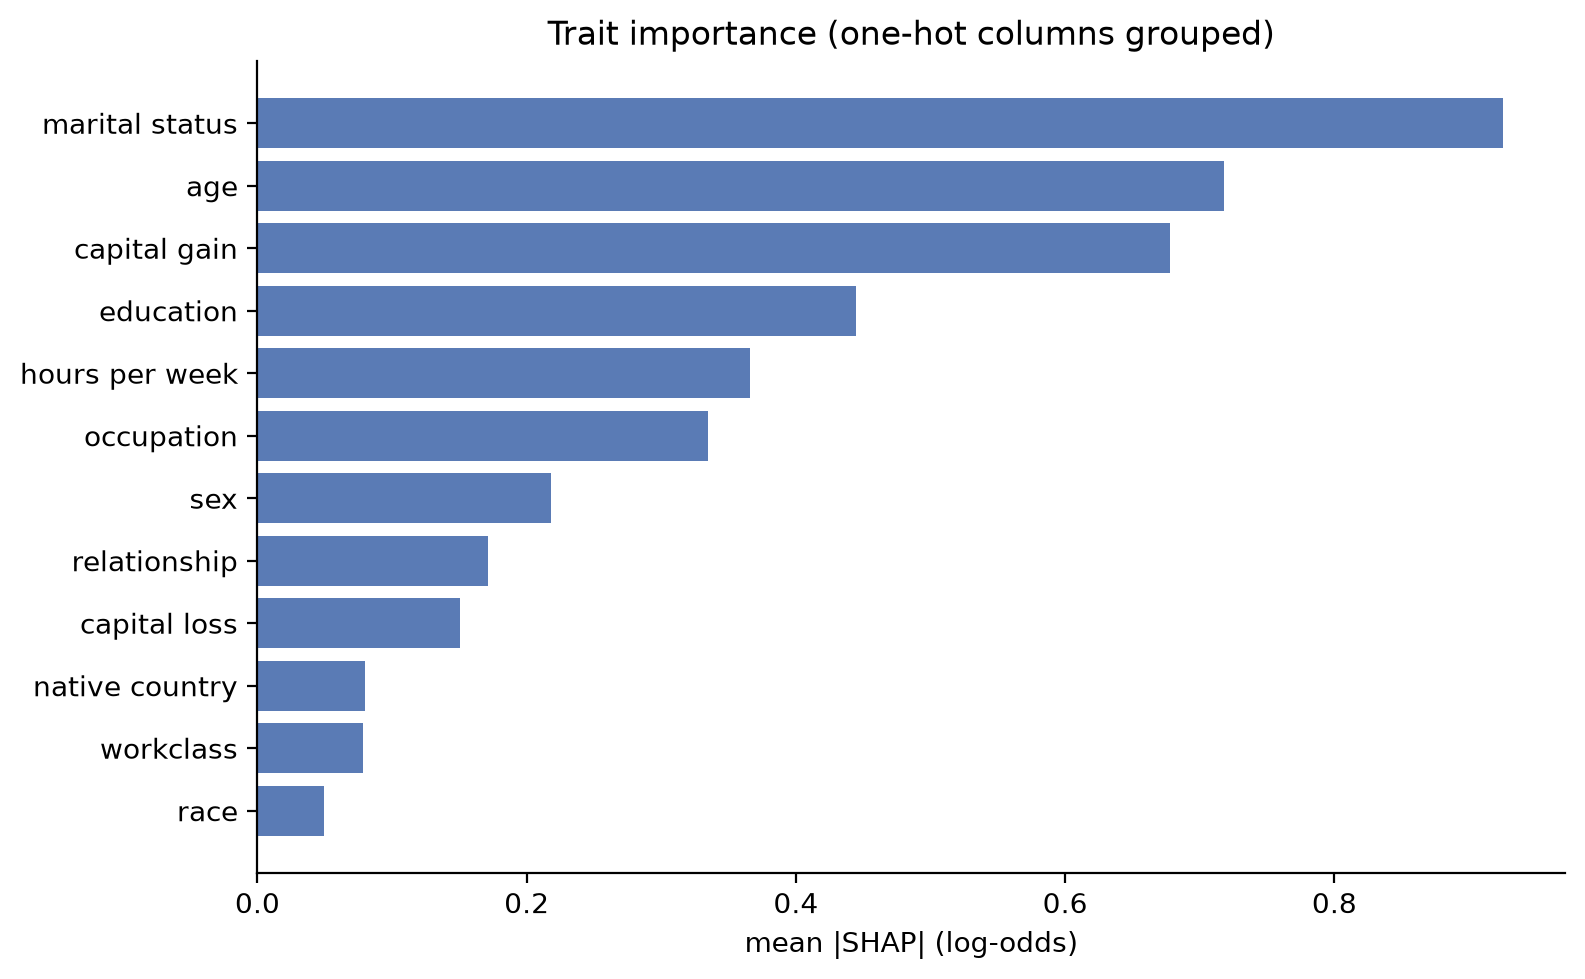

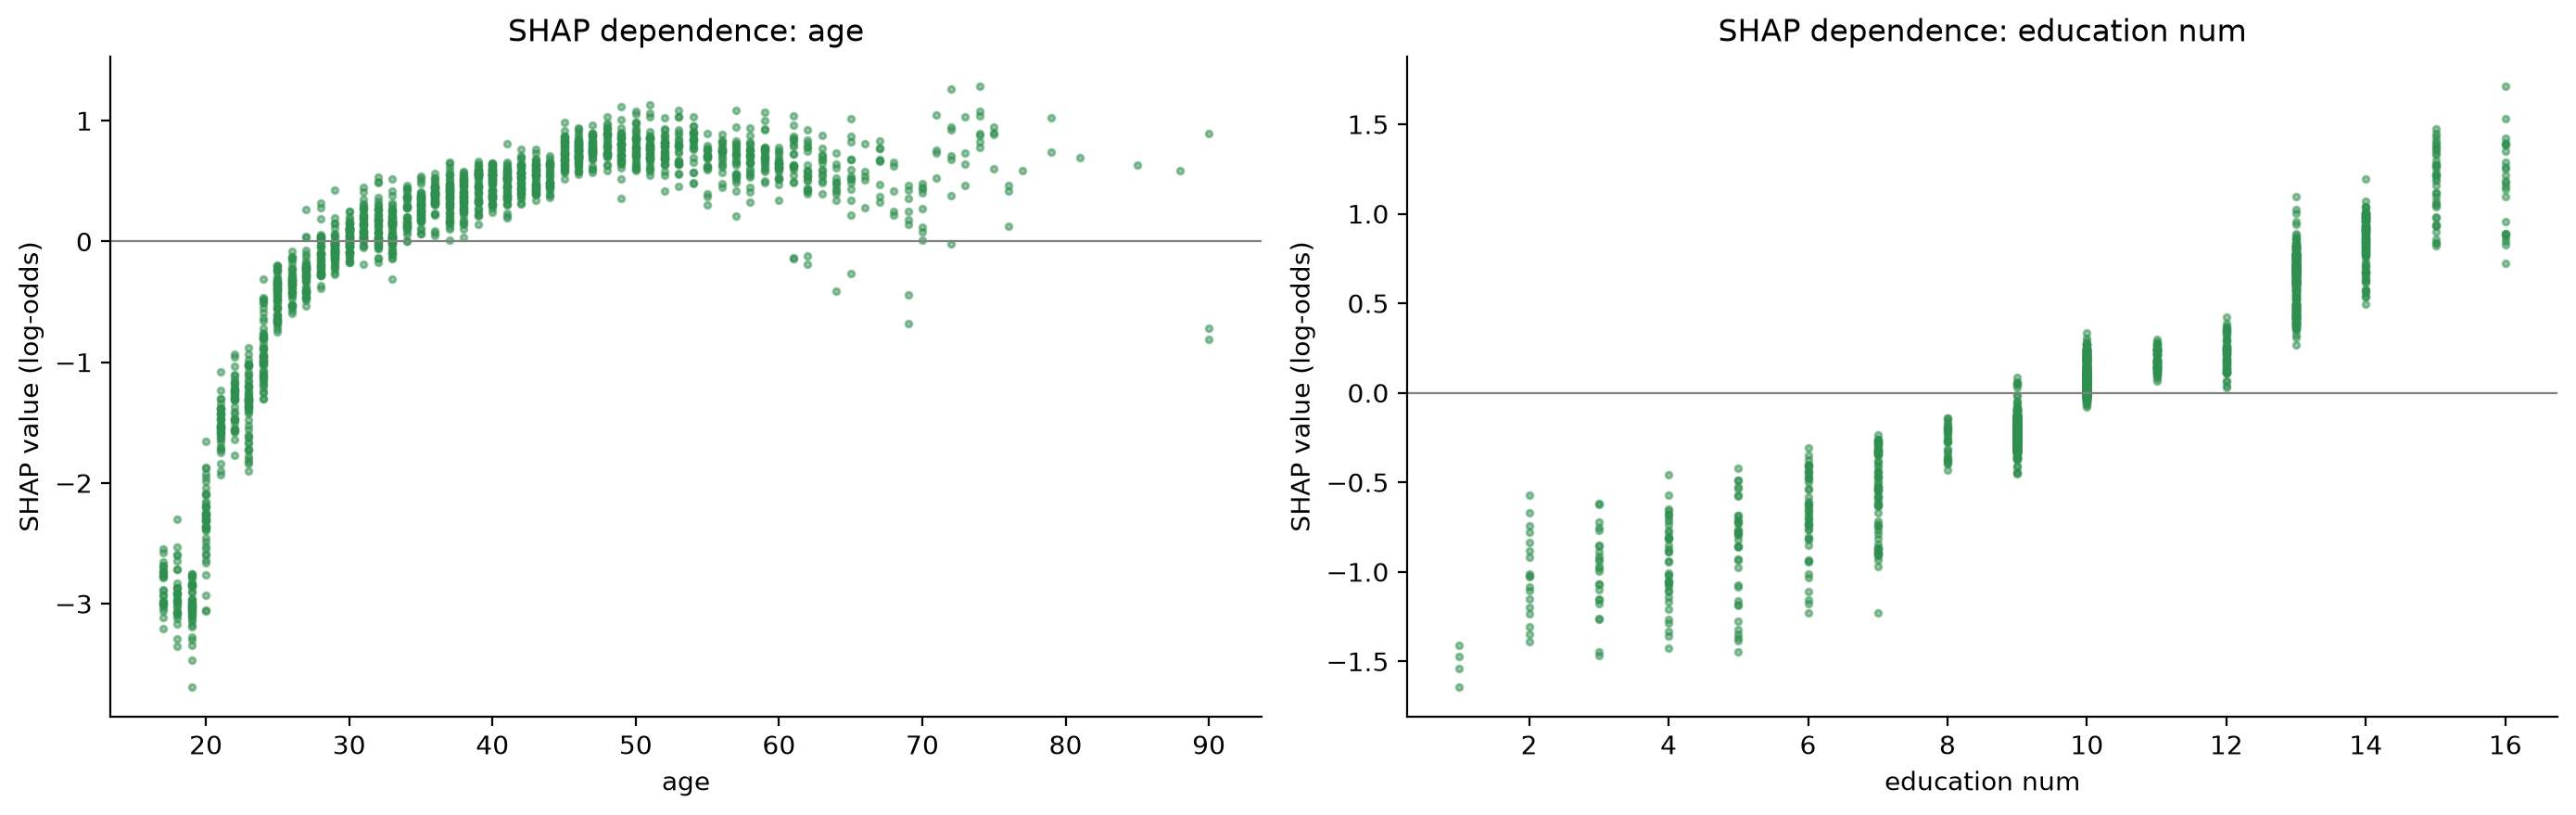

<IPython.core.display.Latex object>

In [14]:
# One-hot columns belong to one original trait; summing their SHAP values gives per-trait importance.
def trait_of(column):
    for trait in schema["categorical_columns"]:
        if column.startswith(trait + "_"):
            return trait
    return column

grouped = pd.DataFrame(explanation.values, columns=sample.columns).T.groupby(trait_of).sum().T
importance = grouped.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index.str.replace("_", " "), importance.values, color="#5a7bb5")
ax.set_xlabel("mean |SHAP| (log-odds)"); ax.set_title("Trait importance (one-hot columns grouped)")
save_fig(fig, "shap_trait_importance")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, column in zip(axes, ["age", "education_num"]):
    ax.scatter(sample[column], explanation[:, column].values, s=6, alpha=0.5, color="#2f8f4e")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xlabel(column.replace("_", " ")); ax.set_ylabel("SHAP value (log-odds)")
    ax.set_title(f"SHAP dependence: {column.replace('_', ' ')}")
save_fig(fig, "shap_dependence")
save_tex("table_trait_importance", importance.sort_values(ascending=False).round(4).rename("mean |SHAP|").to_frame()
         .to_latex(caption="Mean absolute SHAP value per trait (log-odds).", label="tab:shap", float_format="%.4f"))

## 7. Temporal inflation adjustment (applied by the BFF)

The model is frozen in 1994 dollars. The only money-valued inputs are `capital_gain` and `capital_loss`; the BFF
converts them from the story year's dollars into 1994 dollars with the BLS CPI-U annual average (series
CUUR0000SA0). Years after the last published value (2024) are projected at a documented **2.5 % per year**. The
same conversion gives the story-year equivalent of the model's \$50K target.

In [15]:
# Same table as bff-api/src/core/domain/services/consumer-price-index.ts (BLS CPI-U, 1982-84 = 100).
CPI = {1990: 130.7, 1991: 136.2, 1992: 140.3, 1993: 144.5, 1994: 148.2, 1995: 152.4, 1996: 156.9, 1997: 160.5,
       1998: 163.0, 1999: 166.6, 2000: 172.2, 2001: 177.1, 2002: 179.9, 2003: 184.0, 2004: 188.9, 2005: 195.3,
       2006: 201.6, 2007: 207.342, 2008: 215.303, 2009: 214.537, 2010: 218.056, 2011: 224.939, 2012: 229.594,
       2013: 232.957, 2014: 236.736, 2015: 237.017, 2016: 240.007, 2017: 245.120, 2018: 251.107, 2019: 255.657,
       2020: 258.811, 2021: 270.970, 2022: 292.655, 2023: 304.702, 2024: 313.689}
LAST, RATE = max(CPI), 0.025

def cpi(year):
    return CPI[year] if year in CPI else CPI[LAST] * (1 + RATE) ** (year - LAST)

years = [1994, 2010, 2024, 2026, 2030, 2040]
table = pd.DataFrame({"year": years, "CPI-U": [round(cpi(y), 2) for y in years],
                      "factor to 1994 $": [round(cpi(1994) / cpi(y), 4) for y in years],
                      "equivalent of $50K (1994)": [f"${50000 * cpi(y) / cpi(1994):,.0f}" for y in years],
                      "source": ["BLS" if y in CPI else "projected 2.5%/yr" for y in years]})
display(table)
cpi_latex = table.to_latex(index=False, caption="CPI-U deflation factors and the story-year equivalent of the model's 50K threshold (USD).",
                           label="tab:cpi", formatters={"CPI-U": "{:.2f}".format, "factor to 1994 $": "{:.4f}".format})
# Escape LaTeX specials in cell text: '$' starts math mode and '%' starts a comment.
save_tex("table_cpi", tex_table(cpi_latex))
save_tex("eq_inflation", r'''
\begin{align}
\text{CPI}(t) &= \begin{cases} \text{CPI}^{\text{BLS}}(t) & t \le %d \\ \text{CPI}^{\text{BLS}}(%d)\,(1 + %.3f)^{\,t - %d} & t > %d \end{cases} \\
x^{(1994)} &= x^{(t)} \cdot \frac{\text{CPI}(1994)}{\text{CPI}(t)}, \qquad x \in \{\text{capital\_gain}, \text{capital\_loss}\} \\
\text{Threshold}^{(t)} &= 50\,000 \cdot \frac{\text{CPI}(t)}{\text{CPI}(1994)} \qquad \text{e.g. } t = 2026:\ \$%s
\end{align}
''' % (LAST, LAST, RATE, LAST, LAST, f"{50000 * cpi(2026) / cpi(1994):,.0f}"))

,year,CPI-U,factor to 1994 $,equivalent of $50K (1994),source
0,1994,148.20,1.0000,"$50,000",BLS
1,2010,218.06,0.6796,"$73,568",BLS
2,2024,313.69,0.4724,"$105,833",BLS
3,2026,329.57,0.4497,"$111,191",projected 2.5%/yr
4,2030,363.78,0.4074,"$122,734",projected 2.5%/yr
5,2040,465.67,0.3182,"$157,110",projected 2.5%/yr


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [16]:
written = sorted(p.name for p in FIG.glob("*.png")) + sorted(p.name for p in TEX.glob("*.tex"))
print(f"{len(written)} files written to artifacts/figures and artifacts/latex:")
print("\n".join(f"  {name}" for name in written))

25 files written to artifacts/figures and artifacts/latex:
  calibration_smote_vs_natural.png
  calibration_test.png
  confusion_matrices.png
  decision_policy.png
  eda_numeric_distributions.png
  eda_rate_by_category.png
  shap_beeswarm.png
  shap_dependence.png
  shap_trait_importance.png
  smote_class_balance.png
  eq_game_accuracy.tex
  eq_gradient_boosting.tex
  eq_inflation.tex
  eq_metrics.tex
  eq_selective_classification.tex
  eq_shapley.tex
  eq_smote.tex
  eq_stacking.tex
  eq_wilson.tex
  table_cpi.tex
  table_data.tex
  table_models.tex
  table_results.tex
  table_smote_ablation.tex
  table_trait_importance.tex
